# Paso 1: Filtro Inicial de Acciones

### Fase 1.1: Descarga y Filtrado de Acciones por Volumen Promedio

In [31]:
import pandas as pd
import numpy as np
import yfinance as yf
import warnings
import requests
from io import StringIO

# Ignorar warnings para una salida más limpia
warnings.filterwarnings('ignore', category=FutureWarning)

print("Obteniendo la lista de tickers del S&P 500 desde Wikipedia...")
url = 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies'
# Usar requests con un User-Agent personalizado para evitar el error 403
header = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/91.0.4472.124 Safari/537.36"}
response = requests.get(url, headers=header)
# pandas >= 2.1 requiere envolver el HTML en StringIO (pasar el texto directo falla en pandas 3)
tabla_sp500 = pd.read_html(StringIO(response.text))[0]
# Reemplazar puntos por guiones para la compatibilidad con yfinance (ej. BRK.B -> BRK-B)
tickers_muestra = tabla_sp500['Symbol'].str.replace('.', '-', regex=False).tolist()

# Diccionario para almacenar las acciones que pasen el filtro
acciones_validas = {}

print(f"Descargando datos para {len(tickers_muestra)} acciones usando yfinance (descarga en bloque para mayor velocidad)...")

# Descargar los últimos 5 años en bloque, incluyendo SPY como referencia de mercado.
# auto_adjust=True: 'Close' ya viene ajustado por splits y dividendos (retorno total).
datos_bloque = yf.download(tickers_muestra + ['SPY'], period="5y", progress=False, auto_adjust=True)


def extraer_ticker(ticker):
    """Devuelve el OHLCV de un ticker como DataFrame con columna 'Date'."""
    # Al descargar múltiples tickers, yfinance devuelve un MultiIndex (Precio, Ticker)
    if isinstance(datos_bloque.columns, pd.MultiIndex):
        df = datos_bloque.xs(ticker, axis=1, level=1, drop_level=True).copy()
    else:
        df = datos_bloque.copy()
    df = df.dropna(subset=['Close']).reset_index()
    if 'index' in df.columns and 'Date' not in df.columns:
        df = df.rename(columns={'index': 'Date'})
    return df


# Filtrar acciones que tengan un volumen promedio mayor a 1,000,000
for ticker in tickers_muestra:
    try:
        datos_temp = extraer_ticker(ticker)
        if not datos_temp.empty and 'Volume' in datos_temp.columns:
            if datos_temp['Volume'].mean() > 1_000_000:
                # Ticker en minúsculas para mantener la compatibilidad con el resto del código
                acciones_validas[ticker.lower()] = datos_temp
    except Exception as error:
        print(f"Error procesando {ticker}: {error}")

# SPY se guarda aparte: es el mercado, no una acción candidata
datos_spy = extraer_ticker('SPY')

print(f"Se encontraron {len(acciones_validas)} acciones válidas de {len(tickers_muestra)} analizadas.")
print("Primeras 30 acciones válidas encontradas:", list(acciones_validas.keys())[:30])

Obteniendo la lista de tickers del S&P 500 desde Wikipedia...
Descargando datos para 503 acciones usando yfinance (descarga en bloque para mayor velocidad)...
Se encontraron 421 acciones válidas de 503 analizadas.
Primeras 30 acciones válidas encontradas: ['mmm', 'aos', 'abt', 'abbv', 'acn', 'adbe', 'amd', 'aes', 'afl', 'a', 'apd', 'abnb', 'akam', 'alb', 'are', 'lnt', 'all', 'googl', 'goog', 'mo', 'amzn', 'amcr', 'aee', 'aep', 'axp', 'aig', 'amt', 'awk', 'ame', 'amgn']


### Fase 1.2: Consolidación de Precios de Cierre y Retornos Diarios

In [32]:
# Consolidar los precios de cierre ajustados de las acciones válidas
lista_precios = []
for ticker, df_accion in acciones_validas.items():
    df_temp = df_accion[['Date', 'Close']].copy()
    df_temp['Date'] = pd.to_datetime(df_temp['Date'])
    df_temp = df_temp.rename(columns={'Close': ticker})
    lista_precios.append(df_temp.set_index('Date'))

# Unión 'outer' + filtro de cobertura. Un join='inner' recortaría TODO el historial
# a la fecha de inicio de la acción más reciente (p. ej. una IPO de hace un mes).
df_precios_unidos = pd.concat(lista_precios, axis=1, join='outer').sort_index()
min_obs = int(0.95 * len(df_precios_unidos))
cobertura = df_precios_unidos.notna().sum()
acciones_excluidas = cobertura[cobertura < min_obs].index.tolist()
df_precios_unidos = df_precios_unidos.drop(columns=acciones_excluidas)

# Agregar SPY (ya descargado en la celda anterior) como columna 'Market'
spy_close = datos_spy.set_index(pd.to_datetime(datos_spy['Date']))['Close'].rename('Market')
df_precios_unidos = df_precios_unidos.join(spy_close, how='inner').dropna()

# Calcular retornos diarios
retornos_diarios = df_precios_unidos.pct_change(fill_method=None).dropna()
# Retornos solo de las acciones (sin el mercado); se usa en las fases siguientes
retornos_activos = retornos_diarios.drop(columns=['Market'])

print(f"Acciones excluidas por historial corto (<95% de las fechas): {len(acciones_excluidas)} -> {acciones_excluidas}")
print(f"Rango de datos: {retornos_diarios.index.min().date()} a {retornos_diarios.index.max().date()} "
      f"({len(retornos_diarios)} días, {retornos_activos.shape[1]} acciones)")
print("Primeras filas de los retornos diarios (incluyendo SPY como 'Market'):")
display(retornos_diarios.head())

Acciones excluidas por historial corto (<95% de las fechas): 10 -> ['fdxf', 'gehc', 'gev', 'hona', 'q', 'rddt', 'sndk', 'solv', 'vlto', 'vylr']
Rango de datos: 2022-01-20 a 2026-11-18 (1213 días, 411 acciones)
Primeras filas de los retornos diarios (incluyendo SPY como 'Market'):


,mmm,aos,abt,abbv,acn,adbe,amd,aes,afl,a,...,wsm,wmb,wday,wynn,xel,xyl,yum,zbh,zts,Market
Date,,,,,,,,,,,,,,,,,,,,,
2022-01-20,-0.027510,-0.016845,-0.010631,-0.016123,-0.003055,-0.011092,-0.049739,0.013871,-0.013703,-0.006765,...,-0.031320,-0.008956,0.009260,-0.022008,0.000881,-0.018340,-0.007068,-0.001866,0.006880,-0.011068
2022-01-21,-0.005301,-0.017773,0.008981,-0.007893,-0.020602,-0.021415,-0.025269,-0.018812,-0.016801,-0.014124,...,0.000000,-0.000348,-0.024149,-0.016648,0.000587,0.005351,0.005015,-0.004064,-0.008071,-0.019631
2022-01-24,0.000869,0.025514,-0.015974,0.001364,0.010041,0.039507,-0.019190,-0.015686,0.010187,0.004436,...,0.086618,-0.017038,0.007896,-0.009924,-0.011580,0.004669,0.016903,0.009058,-0.001298,0.004247
2022-01-25,0.005498,-0.042904,-0.004442,0.007037,-0.011947,-0.032598,-0.046340,-0.018592,0.006832,-0.025702,...,0.008326,0.024761,-0.046521,0.019576,0.006674,-0.034576,-0.033956,-0.021836,-0.024092,-0.012209
2022-01-26,-0.025611,-0.009019,-0.025959,0.008565,-0.015107,-0.003799,-0.003779,0.011277,0.004200,-0.007877,...,-0.041096,0.008284,-0.046885,-0.003817,-0.003830,-0.012804,-0.015649,-0.003803,-0.027708,-0.002509


# Paso 2: Análisis Fundamental y Modelos Financieros

### Fase 2.1: Cálculo del CAPM y Beta de Hamada

In [33]:
import yfinance as yf
import pandas as pd
import numpy as np

# Definir variables financieras de tasa libre de riesgo y retorno de mercado
tasa_libre_riesgo_anual = 0.04
tasa_impuestos = 0.21
retorno_mercado_anual = retornos_diarios['Market'].mean() * 252
varianza_mercado = retornos_diarios['Market'].var() * 252
prima_mercado = retorno_mercado_anual - tasa_libre_riesgo_anual

metricas_acciones = []

print("Calculando métricas y consultando Debt-to-Equity en Yahoo Finance (puede tardar un momento)...")

for ticker in retornos_activos.columns:
    # Beta histórica (apalancada) = Cov(activo, mercado) / Var(mercado)
    covarianza_activo_mercado = retornos_activos[ticker].cov(retornos_diarios['Market']) * 252
    beta_apalancada = covarianza_activo_mercado / varianza_mercado

    # Retorno esperado usando CAPM tradicional
    retorno_esperado_capm = tasa_libre_riesgo_anual + beta_apalancada * prima_mercado

    # Ratio real de Deuda/Capital (D/E). Si no hay dato válido se deja NaN (sin valores inventados).
    # Nota: para bancos/aseguradoras el D/E no es económicamente significativo.
    relacion_deuda_capital = np.nan
    try:
        de_ratio = yf.Ticker(ticker.upper()).info.get('debtToEquity')
        # yfinance entrega el ratio en porcentaje; D/E negativo (capital contable negativo) no es válido para Hamada
        if de_ratio is not None and de_ratio >= 0:
            relacion_deuda_capital = de_ratio / 100.0
    except Exception:
        pass

    # Beta desapalancada de Hamada (riesgo del negocio sin deuda): B_U = B_L / (1 + (1 - t) * D/E)
    beta_desapalancada = beta_apalancada / (1 + (1 - tasa_impuestos) * relacion_deuda_capital)

    metricas_acciones.append({
        'Activo': ticker,
        'Beta_Apalancada': beta_apalancada,
        'Retorno_Esperado_CAPM': retorno_esperado_capm,
        'Relacion_D_E': relacion_deuda_capital,
        'DE_Disponible': not np.isnan(relacion_deuda_capital),
        'Beta_Hamada_Desapalancada': beta_desapalancada,
    })

df_metricas_fundamentales = pd.DataFrame(metricas_acciones)

# La beta desapalancada no se usa directo en el CAPM: se re-apalanca a una estructura de
# capital objetivo (aquí, la mediana del D/E del universo) para obtener la beta del accionista.
de_objetivo = df_metricas_fundamentales['Relacion_D_E'].median()
df_metricas_fundamentales['Beta_Reapalancada'] = (
    df_metricas_fundamentales['Beta_Hamada_Desapalancada'] * (1 + (1 - tasa_impuestos) * de_objetivo)
)
df_metricas_fundamentales['Retorno_Esperado_Hamada'] = (
    tasa_libre_riesgo_anual + df_metricas_fundamentales['Beta_Reapalancada'] * prima_mercado
)

print(f"Retorno de mercado anualizado (SPY): {retorno_mercado_anual:.2%} | D/E objetivo (mediana): {de_objetivo:.2f}")
print(f"Acciones sin D/E válido: {(~df_metricas_fundamentales['DE_Disponible']).sum()}")
print("--- Análisis de CAPM y Beta de Hamada ---")
display(df_metricas_fundamentales)

Calculando métricas y consultando Debt-to-Equity en Yahoo Finance (puede tardar un momento)...
Retorno de mercado anualizado (SPY): 12.80% | D/E objetivo (mediana): 0.74
Acciones sin D/E válido: 44
--- Análisis de CAPM y Beta de Hamada ---


,Activo,Beta_Apalancada,Retorno_Esperado_CAPM,Relacion_D_E,DE_Disponible,Beta_Hamada_Desapalancada,Beta_Reapalancada,Retorno_Esperado_Hamada
0,mmm,0.851075,0.114897,3.03502,True,0.250488,0.396354,0.074880
1,aos,0.801309,0.110518,0.39219,True,0.611766,0.968012,0.125188
2,abt,0.489186,0.083050,0.60899,True,0.330285,0.522618,0.085992
3,abbv,0.287928,0.065339,NaN,False,NaN,NaN,NaN
4,acn,0.871644,0.116708,0.40283,True,0.661220,1.046265,0.132075
...,...,...,...,...,...,...,...,...
406,xel,0.310336,0.067311,1.67652,True,0.133509,0.211255,0.058591
407,xyl,0.945099,0.123172,0.28789,True,0.769980,1.218359,0.147220
408,yum,0.492471,0.083339,NaN,False,NaN,NaN,NaN
409,zbh,0.586815,0.091642,0.60172,True,0.397744,0.629360,0.095386


# Paso 3: Análisis Técnico con Indicadores

### Fase 3.1: Medias Móviles, RSI, MACD y Oscilador Estocástico

Acciones que muestran perfil 'Saliendo de Sobreventa':
['alb', 'googl', 'goog', 'amcr', 'aptv', 'ba', 'cdns', 'ccl', 'carr', 'glw', 'ddog', 'deck', 'dash', 'etn', 'eqt', 'p', 'expe', 'ftnt', 'fcx', 'gev', 'hpe', 'intc', 'iff', 'jbl', 'len', 'lite', 'mkc', 'mchp', 'mu', 'nflx', 'nke', 'nsc', 'pltr', 'rddt', 'rvty', 'hood', 'rost', 'stx', 'sre', 'now', 'smci', 'ter', 'trmb', 'twlo', 'veev', 'wdc']

Mostrando el gráfico de la primera acción encontrada: ALB


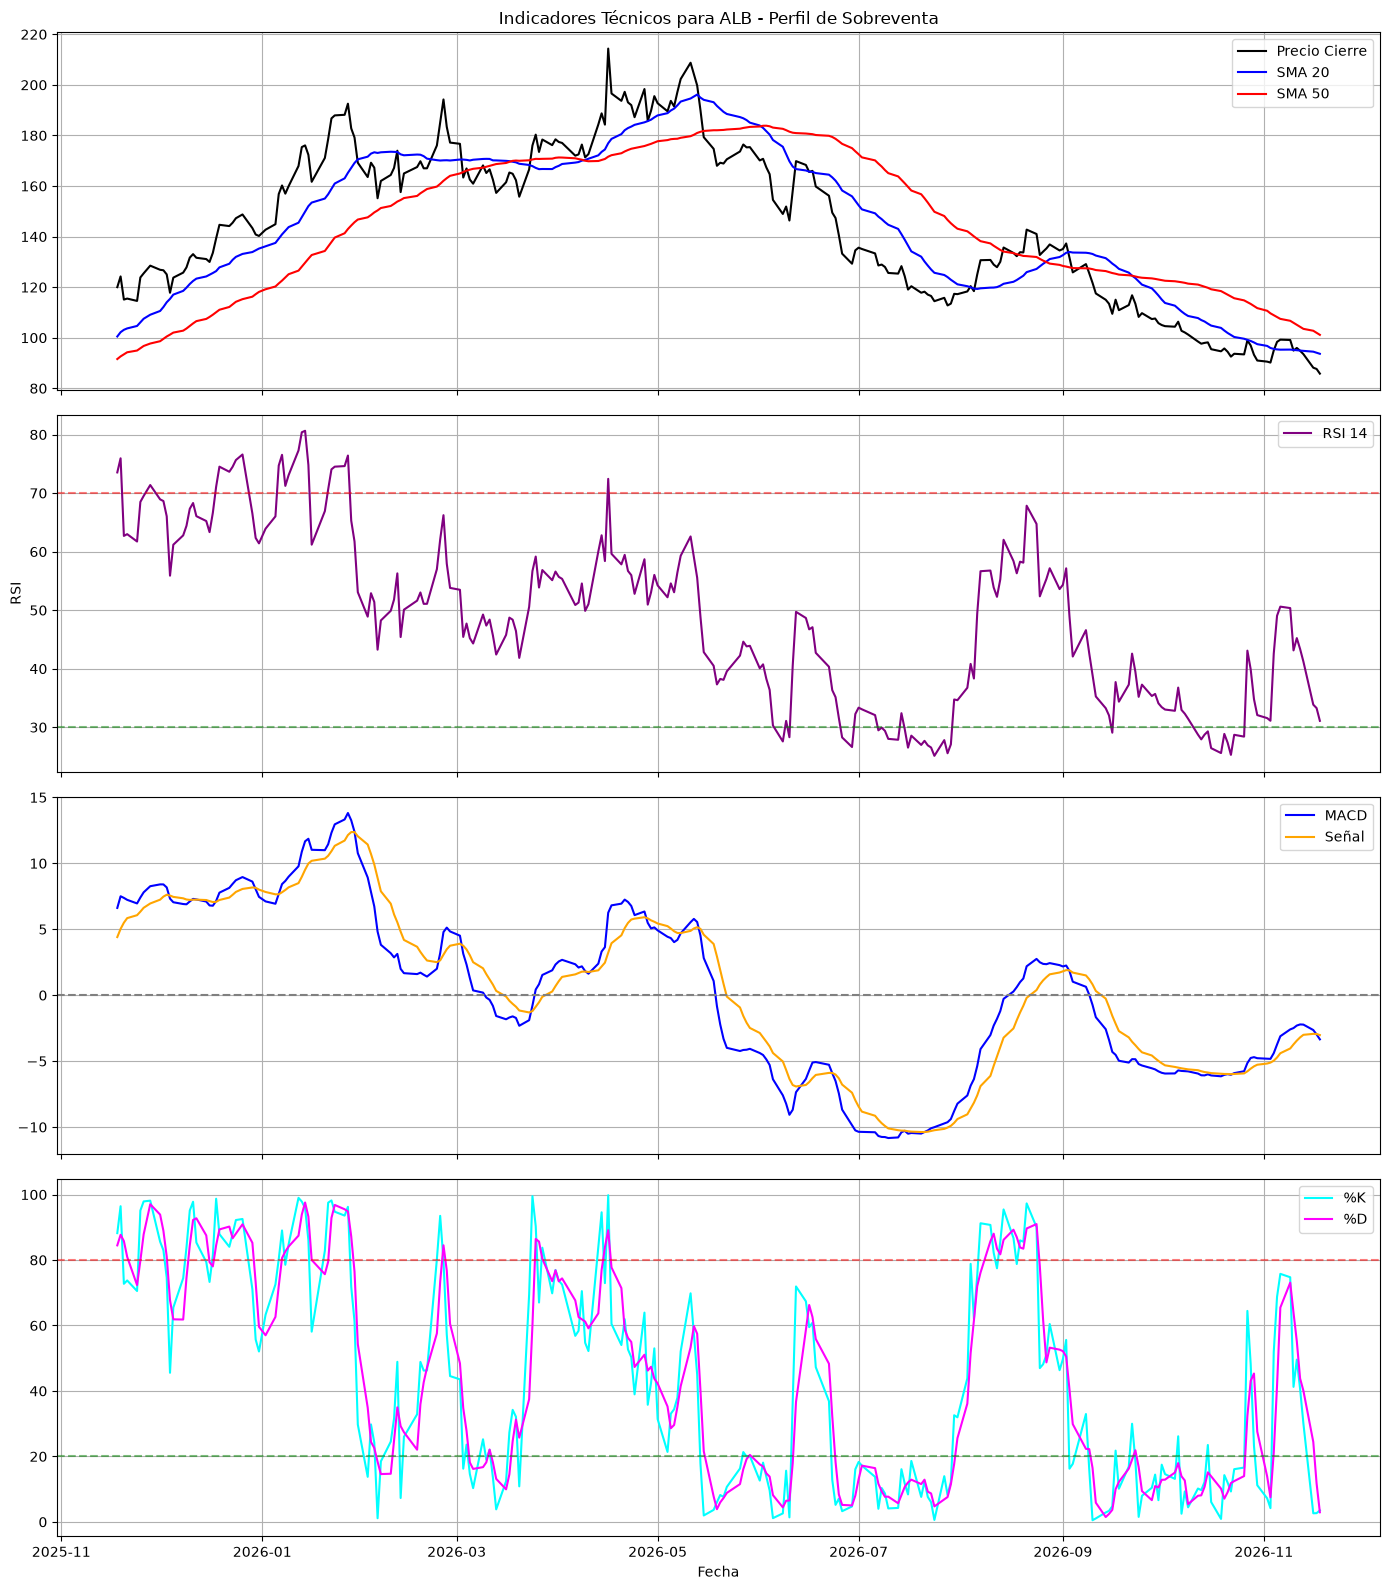

In [34]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np


def calcular_rsi(precios, n=14):
    """RSI de Wilder (suavizado exponencial alpha = 1/n). Se usa en todo el notebook."""
    delta = precios.diff()
    ganancia = delta.clip(lower=0).ewm(alpha=1/n, adjust=False).mean()
    perdida = (-delta.clip(upper=0)).ewm(alpha=1/n, adjust=False).mean()
    rs = ganancia / perdida
    return 100 - (100 / (1 + rs))


# Escáner: Buscar acciones saliendo de sobreventa
acciones_sobreventa = []
indicadores_sobreventa = {}

for ticker, df_accion in acciones_validas.items():
    df_tecnico = df_accion.copy()
    df_tecnico['Date'] = pd.to_datetime(df_tecnico['Date'])
    df_tecnico = df_tecnico.sort_values('Date').set_index('Date')

    # RSI 14 (Wilder)
    df_tecnico['RSI_14'] = calcular_rsi(df_tecnico['Close'], 14)

    # Oscilador Estocástico
    minimo_14 = df_tecnico['Low'].rolling(window=14).min()
    maximo_14 = df_tecnico['High'].rolling(window=14).max()
    # Evitar división entre cero si el máximo y el mínimo de 14 días coinciden
    rango_14 = (maximo_14 - minimo_14).replace(0, np.nan)
    df_tecnico['Estocastico_K'] = 100 * ((df_tecnico['Close'] - minimo_14) / rango_14)
    df_tecnico['Estocastico_D'] = df_tecnico['Estocastico_K'].rolling(window=3).mean()

    # MACD
    ema_12 = df_tecnico['Close'].ewm(span=12, adjust=False).mean()
    ema_26 = df_tecnico['Close'].ewm(span=26, adjust=False).mean()
    df_tecnico['MACD'] = ema_12 - ema_26
    df_tecnico['MACD_Senal'] = df_tecnico['MACD'].ewm(span=9, adjust=False).mean()

    # Medias Móviles Simples (SMA 20 y 50)
    df_tecnico['SMA_20'] = df_tecnico['Close'].rolling(window=20).mean()
    df_tecnico['SMA_50'] = df_tecnico['Close'].rolling(window=50).mean()

    indicadores_sobreventa[ticker] = df_tecnico

    # Condiciones de salida de sobreventa (últimos 2 días)
    if len(df_tecnico) > 2:
        ultimo_rsi = df_tecnico['RSI_14'].iloc[-1]
        penultimo_rsi = df_tecnico['RSI_14'].iloc[-2]

        ultima_K = df_tecnico['Estocastico_K'].iloc[-1]
        ultima_D = df_tecnico['Estocastico_D'].iloc[-1]
        penultima_K = df_tecnico['Estocastico_K'].iloc[-2]
        penultima_D = df_tecnico['Estocastico_D'].iloc[-2]

        # 1. RSI estaba cerca o debajo de 30 y ahora está subiendo (pero aún por debajo de 45)
        criterio_rsi = (ultimo_rsi > penultimo_rsi) and (ultimo_rsi < 45) and (penultimo_rsi < 35)

        # 2. Estocástico cruzando al alza en zona de sobreventa (< 30)
        criterio_estocastico = (ultima_K > ultima_D) and (penultima_K <= penultima_D) and (ultima_K < 30)

        if criterio_rsi or criterio_estocastico:
            acciones_sobreventa.append(ticker)

print("Acciones que muestran perfil 'Saliendo de Sobreventa':")
print(acciones_sobreventa)

if acciones_sobreventa:
    activo_tecnico = acciones_sobreventa[0]
    print(f"\nMostrando el gráfico de la primera acción encontrada: {activo_tecnico.upper()}")
else:
    activo_tecnico = list(acciones_validas.keys())[0]
    print(f"\nNo se encontraron acciones con ese perfil exacto hoy. Mostrando: {activo_tecnico.upper()}")

df_tecnico = indicadores_sobreventa[activo_tecnico]

# Visualización gráfica de los indicadores
df_grafico = df_tecnico.tail(252) # Último año bursátil
fig, (ax1, ax2, ax3, ax4) = plt.subplots(4, 1, figsize=(14, 16), sharex=True)

# Gráfico 1: Precios y Medias Móviles
ax1.plot(df_grafico.index, df_grafico['Close'], label='Precio Cierre', color='black')
ax1.plot(df_grafico.index, df_grafico['SMA_20'], label='SMA 20', color='blue')
ax1.plot(df_grafico.index, df_grafico['SMA_50'], label='SMA 50', color='red')
ax1.set_title(f'Indicadores Técnicos para {activo_tecnico.upper()} - Perfil de Sobreventa')
ax1.legend()
ax1.grid(True)

# Gráfico 2: RSI
ax2.plot(df_grafico.index, df_grafico['RSI_14'], color='purple', label='RSI 14')
ax2.axhline(70, color='red', linestyle='--', alpha=0.5)
ax2.axhline(30, color='green', linestyle='--', alpha=0.5)
ax2.set_ylabel('RSI')
ax2.legend()
ax2.grid(True)

# Gráfico 3: MACD
ax3.plot(df_grafico.index, df_grafico['MACD'], color='blue', label='MACD')
ax3.plot(df_grafico.index, df_grafico['MACD_Senal'], color='orange', label='Señal')
ax3.axhline(0, color='gray', linestyle='--')
ax3.legend()
ax3.grid(True)

# Gráfico 4: Estocástico
ax4.plot(df_grafico.index, df_grafico['Estocastico_K'], color='cyan', label='%K')
ax4.plot(df_grafico.index, df_grafico['Estocastico_D'], color='magenta', label='%D')
ax4.axhline(80, color='red', linestyle='--', alpha=0.5)
ax4.axhline(20, color='green', linestyle='--', alpha=0.5)
ax4.legend()
ax4.grid(True)

plt.xlabel('Fecha')
plt.tight_layout()
plt.show()

### Fase 3.2: Categorización de Activos por Volatilidad y Direccionalidad
En esta fase clasificamos dinámicamente las acciones del universo analizado de acuerdo con dos dimensiones clave:
1. **Volatilidad Anualizada**: Clasificadas en *Alta Volatilidad* o *Baja Volatilidad* utilizando el valor medio de volatilidad como umbral.
2. **Direccionalidad (RSI)**: Clasificadas en tendencia *Alcista* (RSI de 14 días > 50) o *Bajista* (RSI de 14 días <= 50).

In [35]:
# 1. Calcular volatilidad histórica anualizada para todos los activos
volatilidades = retornos_activos.std() * np.sqrt(252)
umbral_volatilidad = volatilidades.median()

# 2. Calcular el último RSI_14 para cada activo (retornos_activos se define en la Fase 1.2)
rsis_actuales = {}
for ticker, df_accion in acciones_validas.items():
    if ticker not in retornos_activos.columns:
        continue
    precios_close = df_accion.sort_values('Date')['Close']
    # RSI de Wilder (misma función que en la Fase 3.1)
    rsis_actuales[ticker] = calcular_rsi(precios_close, 14).iloc[-1]

# 3. Clasificar según condiciones cuantitativas
categorias_acciones = []
for ticker in volatilidades.index:
    vol = volatilidades[ticker]
    rsi = rsis_actuales.get(ticker, 50.0)

    # Determinar categoría de volatilidad
    cat_vol = "Alta Volatilidad" if vol > umbral_volatilidad else "Baja Volatilidad"

    # Determinar dirección de la tendencia
    cat_dir = "Alcista" if rsi > 50 else "Bajista"

    categorias_acciones.append({
        'Activo': ticker,
        'Volatilidad_Anualizada': vol,
        'RSI_Actual': rsi,
        'Categoria_Volatilidad': cat_vol,
        'Direccionalidad': cat_dir,
        'Cuadrante': f"{cat_vol} - {cat_dir}"
    })

df_categorizacion = pd.DataFrame(categorias_acciones)
print("--- Clasificación Cuantitativa de Activos ---")
display(df_categorizacion.sort_values(by='Cuadrante'))

--- Clasificación Cuantitativa de Activos ---


,Activo,Volatilidad_Anualizada,RSI_Actual,Categoria_Volatilidad,Direccionalidad,Cuadrante
6,amd,0.592192,50.338638,Alta Volatilidad,Alcista,Alta Volatilidad - Alcista
7,aes,0.374758,74.851262,Alta Volatilidad,Alcista,Alta Volatilidad - Alcista
9,a,0.308662,55.255347,Alta Volatilidad,Alcista,Alta Volatilidad - Alcista
11,abnb,0.438138,53.831522,Alta Volatilidad,Alcista,Alta Volatilidad - Alcista
12,akam,0.405194,51.521951,Alta Volatilidad,Alcista,Alta Volatilidad - Alcista
...,...,...,...,...,...,...
389,vici,0.208837,49.928196,Baja Volatilidad,Bajista,Baja Volatilidad - Bajista
398,wfc,0.292671,39.267311,Baja Volatilidad,Bajista,Baja Volatilidad - Bajista
401,wy,0.268858,46.460469,Baja Volatilidad,Bajista,Baja Volatilidad - Bajista
403,wmb,0.245912,42.699134,Baja Volatilidad,Bajista,Baja Volatilidad - Bajista


# Paso 4: Análisis Econométrico y Riesgo/Rendimiento

### Fase 4.1: Retornos, Volatilidad, Matriz de Correlación y Cointegración

--- Métricas Econométricas de Activos Individuales ---


,Retorno_Medio_Anual,Varianza_Anual,Volatilidad_Anual,Ratio_Sharpe
mmm,0.118404,0.086936,0.294849,0.265911
aos,0.014203,0.075732,0.275194,-0.093742
abt,0.008426,0.054944,0.234402,-0.134699
abbv,0.218548,0.055757,0.236130,0.756142
acn,-0.012291,0.111021,0.333198,-0.156936
...,...,...,...,...
xel,0.089056,0.043952,0.209647,0.233994
xyl,0.023859,0.076646,0.276849,-0.058302
yum,0.095148,0.046216,0.214979,0.256528
zbh,0.017129,0.077095,0.277661,-0.082370


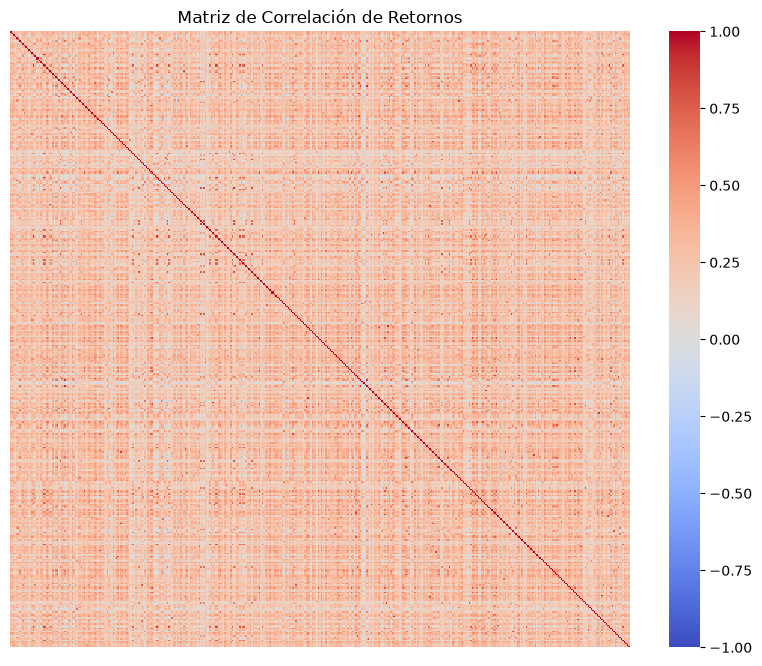


--- Test de Cointegración: mmm vs aos ---
p-valor: 0.9815
No hay evidencia sólida de cointegración.


In [36]:
import seaborn as sns
from statsmodels.tsa.stattools import coint

# retornos_activos (acciones sin 'Market') ya está definido en la Fase 1.2

# Métricas de riesgo y rendimiento
retorno_medio_anual = retornos_activos.mean() * 252
varianza_anual = retornos_activos.var() * 252
volatilidad_anual = retornos_activos.std() * np.sqrt(252)

# Ratio de Sharpe
ratio_sharpe = (retorno_medio_anual - tasa_libre_riesgo_anual) / volatilidad_anual

# Resumen de métricas econométricas
df_econometrico = pd.DataFrame({
    'Retorno_Medio_Anual': retorno_medio_anual,
    'Varianza_Anual': varianza_anual,
    'Volatilidad_Anual': volatilidad_anual,
    'Ratio_Sharpe': ratio_sharpe
})

print("--- Métricas Econométricas de Activos Individuales ---")
display(df_econometrico)

# Matriz de covarianza y correlación
matriz_cov = retornos_activos.cov() * 252
matriz_corr = retornos_activos.corr()

# Visualizar mapa de calor de correlaciones (sin anotaciones: con cientos de activos serían ilegibles)
plt.figure(figsize=(10, 8))
sns.heatmap(matriz_corr, cmap='coolwarm', vmin=-1, vmax=1, xticklabels=False, yticklabels=False)
plt.title('Matriz de Correlación de Retornos')
plt.show()

# Test de Cointegración (ilustrativo): solo el primer par de columnas, no es una búsqueda de pares
simbolos = list(retornos_activos.columns)
if len(simbolos) >= 2:
    activo1, activo2 = simbolos[0], simbolos[1]
    puntos_precio1 = df_precios_unidos[activo1]
    puntos_precio2 = df_precios_unidos[activo2]
    p_valor = coint(puntos_precio1, puntos_precio2)[1]

    print(f"\n--- Test de Cointegración: {activo1} vs {activo2} ---")
    print(f"p-valor: {p_valor:.4f}")
    if p_valor < 0.05:
        print("Existe evidencia de que los activos están cointegrados.")
    else:
        print("No hay evidencia sólida de cointegración.")

# Paso 5: Construcción y Análisis de Portafolios

### Fase 5.1: Portafolio Equiponderado

In [37]:
# Crear pesos iguales para todos los activos
num_activos = len(retornos_activos.columns)
pesos_iguales = np.array([1 / num_activos] * num_activos)

# Calcular rendimiento del portafolio equiponderado
rendimiento_portafolio = np.dot(pesos_iguales, retorno_medio_anual)

# Calcular varianza y volatilidad del portafolio
varianza_portafolio = np.dot(pesos_iguales.T, np.dot(matriz_cov, pesos_iguales))
volatilidad_portafolio = np.sqrt(varianza_portafolio)

# Sharpe Ratio
ratio_sharpe_portafolio = (rendimiento_portafolio - tasa_libre_riesgo_anual) / volatilidad_portafolio

print("--- Métricas del Portafolio Equiponderado ---")
print(f"Retorno Esperado Anualizado: {rendimiento_portafolio:.4f}")
print(f"Volatilidad Anualizada: {volatilidad_portafolio:.4f}")
print(f"Ratio de Sharpe: {ratio_sharpe_portafolio:.4f}")

--- Métricas del Portafolio Equiponderado ---
Retorno Esperado Anualizado: 0.1467
Volatilidad Anualizada: 0.1699
Ratio de Sharpe: 0.6283


# Paso 6: Optimización de Portafolio con SciPy

### Fase 6.1: Frontera Eficiente, GMV y Máximo Sharpe

Frontera eficiente: 50 de 50 puntos resueltos.


,Portafolio,Retorno_Esperado,Volatilidad,Ratio_Sharpe
0,Equiponderado,0.146733,0.169872,0.628317
1,GMV,0.146328,0.105932,1.003733
2,Max Sharpe,0.401332,0.158411,2.280977


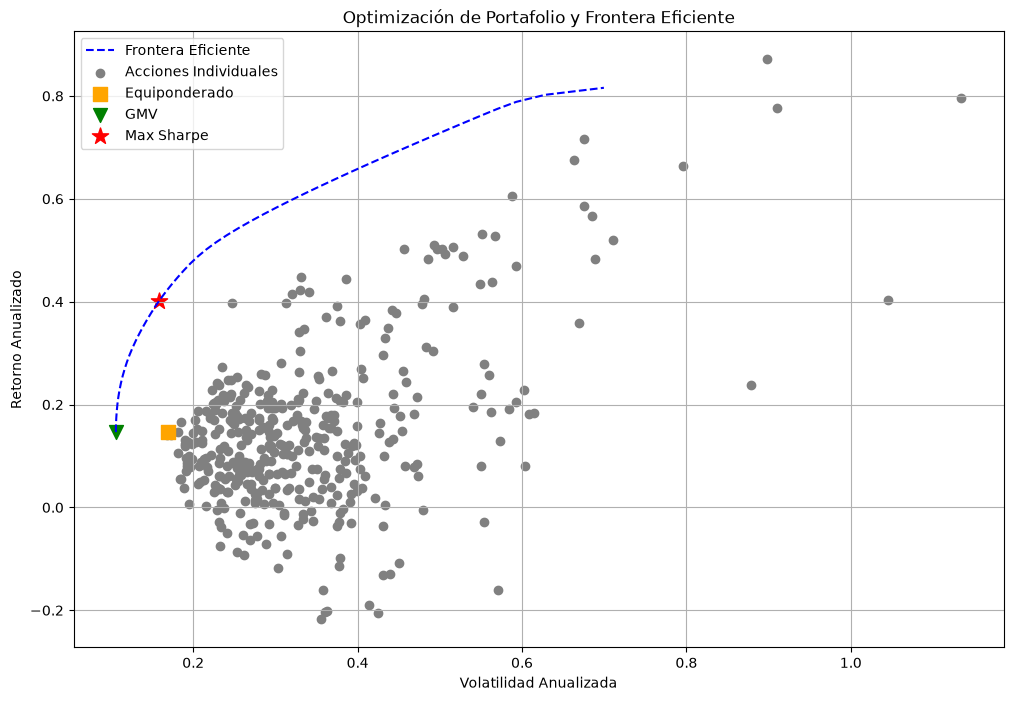

In [38]:
import scipy.optimize as sco

# Función para calcular estadísticas del portafolio dado unos pesos
def calcular_estadisticas_portafolio(pesos):
    pesos = np.array(pesos)
    ret = np.dot(pesos, retorno_medio_anual)
    vol = np.sqrt(np.dot(pesos.T, np.dot(matriz_cov, pesos)))
    sharpe = (ret - tasa_libre_riesgo_anual) / vol
    return np.array([ret, vol, sharpe])

# Funciones a minimizar para las optimizaciones
def minimizar_sharpe(pesos):
    return -calcular_estadisticas_portafolio(pesos)[2]

def minimizar_volatilidad(pesos):
    return calcular_estadisticas_portafolio(pesos)[1]

# Restricciones de pesos (suma de pesos = 1, y límites individuales del 35%)
restricciones = ({'type': 'eq', 'fun': lambda x: np.sum(x) - 1})
limites = tuple((0, 0.35) for _ in range(num_activos))
pesos_iniciales = num_activos * [1. / num_activos,]

# 1. Optimización Máximo Sharpe
opt_max_sharpe = sco.minimize(minimizar_sharpe, pesos_iniciales, method='SLSQP', bounds=limites, constraints=restricciones)
if not opt_max_sharpe.success:
    print(f"AVISO: la optimización de Máximo Sharpe no convergió: {opt_max_sharpe.message}")
pesos_max_sharpe = opt_max_sharpe.x
stats_max_sharpe = calcular_estadisticas_portafolio(pesos_max_sharpe)

# 2. Optimización Mínima Varianza Global (GMV)
opt_gmv = sco.minimize(minimizar_volatilidad, pesos_iniciales, method='SLSQP', bounds=limites, constraints=restricciones)
if not opt_gmv.success:
    print(f"AVISO: la optimización GMV no convergió: {opt_gmv.message}")
pesos_gmv = opt_gmv.x
stats_gmv = calcular_estadisticas_portafolio(pesos_gmv)


# 3. Construcción de la Frontera Eficiente
def retorno_maximo_alcanzable(retornos, limite):
    """Mayor retorno posible con pesos <= limite: llenar primero los activos de mayor retorno."""
    restante, total = 1.0, 0.0
    for r in np.sort(np.asarray(retornos))[::-1]:
        w = min(limite, restante)
        total += w * r
        restante -= w
        if restante <= 1e-12:
            break
    return total


limite_peso = 0.35
r_max = retorno_maximo_alcanzable(retorno_medio_anual, limite_peso)
rendimientos_objetivo = np.linspace(stats_gmv[0], r_max, 50)
rendimientos_frontera = []
volatilidades_frontera = []

for r_obj in rendimientos_objetivo:
    rest_ef = (
        {'type': 'eq', 'fun': lambda x: np.sum(x) - 1},
        {'type': 'eq', 'fun': lambda x, r=r_obj: calcular_estadisticas_portafolio(x)[0] - r}
    )
    opt_ef = sco.minimize(minimizar_volatilidad, pesos_iniciales, method='SLSQP', bounds=limites, constraints=rest_ef)
    # Solo se grafican los puntos donde el optimizador realmente encontró solución
    if opt_ef.success:
        rendimientos_frontera.append(r_obj)
        volatilidades_frontera.append(opt_ef.fun)

print(f"Frontera eficiente: {len(rendimientos_frontera)} de {len(rendimientos_objetivo)} puntos resueltos.")

# Mostrar Resultados Comparativos
df_comparativo = pd.DataFrame({
    'Portafolio': ['Equiponderado', 'GMV', 'Max Sharpe'],
    'Retorno_Esperado': [rendimiento_portafolio, stats_gmv[0], stats_max_sharpe[0]],
    'Volatilidad': [volatilidad_portafolio, stats_gmv[1], stats_max_sharpe[1]],
    'Ratio_Sharpe': [ratio_sharpe_portafolio, stats_gmv[2], stats_max_sharpe[2]]
})
display(df_comparativo)

# Graficar la Frontera Eficiente
plt.figure(figsize=(12, 8))
plt.plot(volatilidades_frontera, rendimientos_frontera, 'b--', label='Frontera Eficiente')
plt.scatter(volatilidad_anual, retorno_medio_anual, color='gray', label='Acciones Individuales')
plt.scatter(volatilidad_portafolio, rendimiento_portafolio, marker='s', color='orange', s=100, label='Equiponderado')
plt.scatter(stats_gmv[1], stats_gmv[0], marker='v', color='green', s=100, label='GMV')
plt.scatter(stats_max_sharpe[1], stats_max_sharpe[0], marker='*', color='red', s=150, label='Max Sharpe')
plt.title('Optimización de Portafolio y Frontera Eficiente')
plt.xlabel('Volatilidad Anualizada')
plt.ylabel('Retorno Anualizado')
plt.legend()
plt.grid(True)
plt.show()

# Paso 7: Simulaciones de Monte Carlo y Recomendaciones Finales

### Fase 7.1: Simulación de Portafolios por Monte Carlo

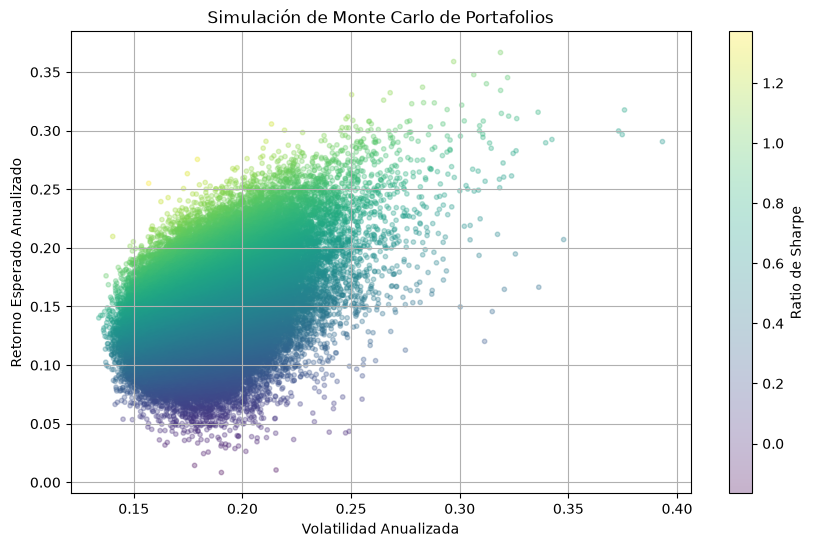

In [39]:
num_simulaciones = 100000
resultados_simulados = np.zeros((3, num_simulaciones))
rng = np.random.default_rng(42)  # semilla para reproducibilidad


def recortar_pesos(pesos, limite, max_iter=100):
    """Recorta los pesos que excedan el límite y reparte el excedente entre el resto."""
    pesos = pesos.copy()
    for _ in range(max_iter):
        exceso = pesos > limite
        if not exceso.any():
            break
        sobrante = (pesos[exceso] - limite).sum()
        pesos[exceso] = limite
        libres = pesos < limite
        pesos[libres] += sobrante * pesos[libres] / pesos[libres].sum()
    return pesos


# Pesos aleatorios con distribución de Dirichlet (alpha pequeño => portafolios concentrados).
# Con cientos de activos, pesos uniformes normalizados colapsarían al portafolio equiponderado.
for i in range(num_simulaciones):
    pesos_aleatorios = rng.dirichlet(np.full(num_activos, 0.05))
    pesos_aleatorios = recortar_pesos(pesos_aleatorios, 0.35)  # suman 1 y ninguno supera el 35%

    resultados_simulados[:, i] = calcular_estadisticas_portafolio(pesos_aleatorios)

# Graficar nube de puntos simulados
plt.figure(figsize=(10, 6))
plt.scatter(resultados_simulados[1], resultados_simulados[0], c=resultados_simulados[2], cmap='viridis', marker='o', s=10, alpha=0.3)
plt.colorbar(label='Ratio de Sharpe')
plt.title('Simulación de Monte Carlo de Portafolios')
plt.xlabel('Volatilidad Anualizada')
plt.ylabel('Retorno Esperado Anualizado')
plt.grid(True)
plt.show()

In [40]:
import pandas as pd
import numpy as np

# 1. Preparar las métricas de cada acción
metricas = []

for ticker in retornos_activos.columns:
    # Rendimiento y Sharpe ya calculados en el entorno
    rendimiento = retorno_medio_anual[ticker]
    sharpe = ratio_sharpe[ticker]
    vol = volatilidad_anual[ticker]

    # Calcular Control Drawdown (calculando Max Drawdown primero)
    precios = df_precios_unidos[ticker]
    maximos_historicos = precios.cummax()
    drawdowns = (precios - maximos_historicos) / maximos_historicos
    max_drawdown = drawdowns.min()  # suele ser un valor negativo
    # Convertimos a Control Drawdown: cuanto menor sea la caída máxima, mayor será este valor
    control_drawdown = 1 + max_drawdown

    # Baja Volatilidad (inversa de la volatilidad, para que a menor vol, mayor puntaje)
    baja_volatilidad = 1 / vol if vol > 0 else 0

    metricas.append({
        'Ticker': ticker,
        'Rendimiento': rendimiento,
        'Sharpe': sharpe,
        'Control_Drawdown': control_drawdown,
        'Baja_Volatilidad': baja_volatilidad
    })

df_metricas = pd.DataFrame(metricas)

# 2. Normalizar métricas (Min-Max) para tenerlas en una escala de 0 a 1
def min_max_norm(serie):
    if serie.max() == serie.min():
        return 1.0
    return (serie - serie.min()) / (serie.max() - serie.min())

df_metricas['Norm_Sharpe'] = min_max_norm(df_metricas['Sharpe'])
df_metricas['Norm_Rendimiento'] = min_max_norm(df_metricas['Rendimiento'])
df_metricas['Norm_Drawdown'] = min_max_norm(df_metricas['Control_Drawdown'])
df_metricas['Norm_Baja_Vol'] = min_max_norm(df_metricas['Baja_Volatilidad'])

# 3. Calcular Score General
# 35% Sharpe + 25% Rendimiento + 25% Control Drawdown + 15% Baja Volatilidad
df_metricas['Score_General'] = (
    0.35 * df_metricas['Norm_Sharpe'] +
    0.25 * df_metricas['Norm_Rendimiento'] +
    0.25 * df_metricas['Norm_Drawdown'] +
    0.15 * df_metricas['Norm_Baja_Vol']
)

# 4. Obtener las top 5 y generar el reporte
top_5 = df_metricas.sort_values(by='Score_General', ascending=False).head(5)

print("=" * 70)
print("                INFORME AUTOMATIZADO: TOP 5 ACCIONES")
print("=" * 70)
print("Fórmula:\nScore General = 35% Sharpe + 25% Rendimiento + 25% Control Drawdown + 15% Baja Volatilidad\n")

reporte = top_5[['Ticker', 'Rendimiento', 'Sharpe', 'Control_Drawdown', 'Baja_Volatilidad', 'Score_General']].copy()
reporte.rename(columns={
    'Rendimiento': 'Retorno Anual',
    'Control_Drawdown': 'Ctrl Drawdown',
    'Baja_Volatilidad': 'Factor Baja Vol'
}, inplace=True)

display(reporte.style.format({
    'Retorno Anual': '{:.2%}',
    'Sharpe': '{:.2f}',
    'Ctrl Drawdown': '{:.2%}',
    'Factor Baja Vol': '{:.2f}',
    'Score_General': '{:.4f}'
}).hide(axis='index'))


                INFORME AUTOMATIZADO: TOP 5 ACCIONES
Fórmula:
Score General = 35% Sharpe + 25% Rendimiento + 25% Control Drawdown + 15% Baja Volatilidad



Ticker,Retorno Anual,Sharpe,Ctrl Drawdown,Factor Baja Vol,Score_General
cah,39.78%,1.45,79.05%,4.05,0.8239
trgp,41.50%,1.17,68.39%,3.12,0.7221
hwm,44.76%,1.23,63.53%,3.02,0.7218
lly,42.27%,1.16,65.52%,3.03,0.7111
trv,22.92%,0.85,81.10%,4.49,0.7081


EJECUTANDO ANÁLISIS INTEGRAL PARA EL TOP 5: ['cah', 'trgp', 'hwm', 'lly', 'trv']

--- 1. Análisis CAPM y Beta (Top 5) ---


,Activo,Beta,Retorno_Esperado_CAPM
0,cah,0.345172,0.070376
1,trgp,0.798944,0.110310
2,hwm,1.117310,0.138327
3,lly,0.551161,0.088504
4,trv,0.396122,0.074860



--- 2. Análisis Técnico Rápido del Líder: CAH ---


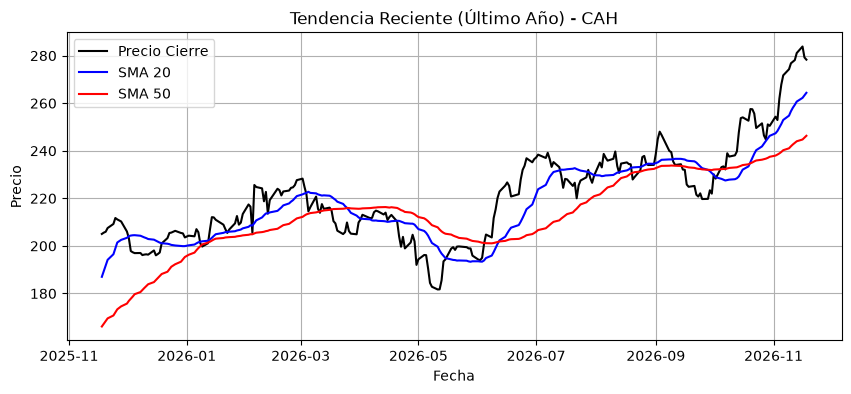


--- 3. Matriz de Correlación Econométrica (Top 5) ---


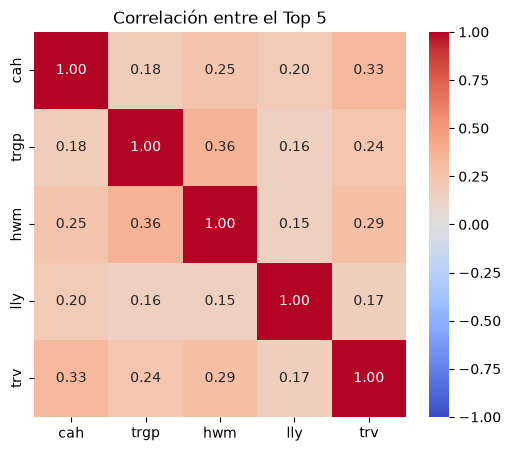


--- 4. Optimización de Portafolio (Top 5) ---
Distribución Óptima (Máximo Sharpe Ratio):
  - CAH: 39.09%
  - TRGP: 18.86%
  - HWM: 17.78%
  - LLY: 21.82%
  - TRV: 2.45%

Retorno Esperado del Portafolio: 41.12%
Volatilidad del Portafolio: 18.78%
Sharpe Ratio: 1.9763

--- 5. Simulación de Monte Carlo (Top 5) ---


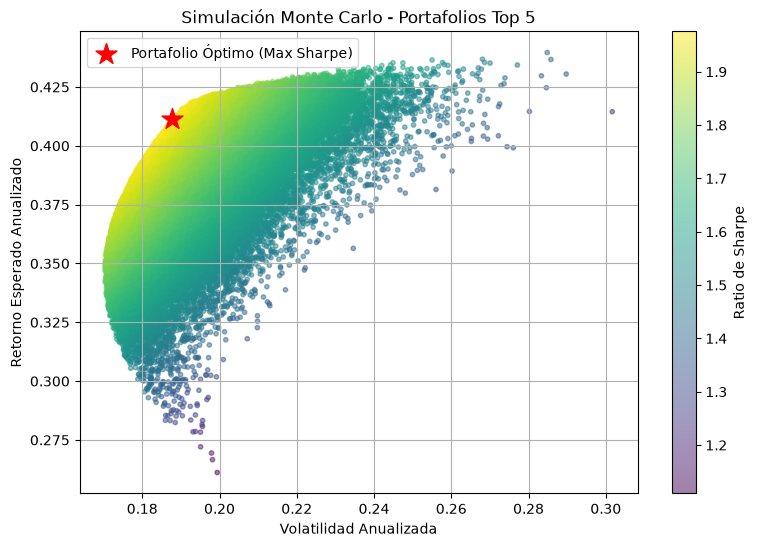

In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.optimize as sco
from statsmodels.tsa.stattools import coint

# 0. Extraer los top 5 tickers
top_tickers = top_5['Ticker'].tolist()
print("=" * 70)
print(f"EJECUTANDO ANÁLISIS INTEGRAL PARA EL TOP 5: {top_tickers}")
print("=" * 70)

# 1. Filtrar retornos y calcular métricas base
retornos_top5 = retornos_activos[top_tickers]
retorno_medio_top5 = retornos_top5.mean() * 252
matriz_cov_top5 = retornos_top5.cov() * 252

# 2. CAPM y Beta
print("\n--- 1. Análisis CAPM y Beta (Top 5) ---")
metricas_capm_top5 = []
for ticker in top_tickers:
    cov_mercado = retornos_activos[ticker].cov(retornos_diarios['Market']) * 252
    beta = cov_mercado / (retornos_diarios['Market'].var() * 252)
    ret_esperado = tasa_libre_riesgo_anual + beta * (retorno_mercado_anual - tasa_libre_riesgo_anual)
    metricas_capm_top5.append({'Activo': ticker, 'Beta': beta, 'Retorno_Esperado_CAPM': ret_esperado})
display(pd.DataFrame(metricas_capm_top5))

# 3. Análisis Técnico del Líder (la acción #1)
lider = top_tickers[0]
print(f"\n--- 2. Análisis Técnico Rápido del Líder: {lider.upper()} ---")
df_lider = acciones_validas[lider].copy()
df_lider['Date'] = pd.to_datetime(df_lider['Date'])
df_lider = df_lider.set_index('Date').sort_index()
df_lider['SMA_20'] = df_lider['Close'].rolling(20).mean()
df_lider['SMA_50'] = df_lider['Close'].rolling(50).mean()

plt.figure(figsize=(10, 4))
plt.plot(df_lider.index[-252:], df_lider['Close'].tail(252), label='Precio Cierre', color='black')
plt.plot(df_lider.index[-252:], df_lider['SMA_20'].tail(252), label='SMA 20', color='blue')
plt.plot(df_lider.index[-252:], df_lider['SMA_50'].tail(252), label='SMA 50', color='red')
plt.title(f'Tendencia Reciente (Último Año) - {lider.upper()}')
plt.xlabel('Fecha')
plt.ylabel('Precio')
plt.legend()
plt.grid(True)
plt.show()

# 4. Matriz de Correlación Top 5
print("\n--- 3. Matriz de Correlación Econométrica (Top 5) ---")
plt.figure(figsize=(6, 5))
sns.heatmap(retornos_top5.corr(), annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt='.2f')
plt.title('Correlación entre el Top 5')
plt.show()

# 5. Optimización de Portafolio (Max Sharpe)
print("\n--- 4. Optimización de Portafolio (Top 5) ---")
num_activos_top5 = len(top_tickers)

def calc_stats_top5(pesos):
    pesos = np.array(pesos)
    ret = np.dot(pesos, retorno_medio_top5)
    vol = np.sqrt(np.dot(pesos.T, np.dot(matriz_cov_top5, pesos)))
    sharpe = (ret - tasa_libre_riesgo_anual) / vol
    return np.array([ret, vol, sharpe])

def min_sharpe_top5(pesos):
    return -calc_stats_top5(pesos)[2]

# Restricciones y límites (0 a 100% por ser portafolio concentrado)
restricciones_top5 = ({'type': 'eq', 'fun': lambda x: np.sum(x) - 1})
limites_top5 = tuple((0, 1.0) for _ in range(num_activos_top5))
pesos_ini_top5 = num_activos_top5 * [1. / num_activos_top5,]

opt_sharpe_top5 = sco.minimize(min_sharpe_top5, pesos_ini_top5, method='SLSQP', bounds=limites_top5, constraints=restricciones_top5)
stats_opt = calc_stats_top5(opt_sharpe_top5.x)

print("Distribución Óptima (Máximo Sharpe Ratio):")
for t, p in zip(top_tickers, opt_sharpe_top5.x):
    print(f"  - {t.upper()}: {p:.2%}")
print(f"\nRetorno Esperado del Portafolio: {stats_opt[0]:.2%}")
print(f"Volatilidad del Portafolio: {stats_opt[1]:.2%}")
print(f"Sharpe Ratio: {stats_opt[2]:.4f}")

# 6. Simulación Monte Carlo
print("\n--- 5. Simulación de Monte Carlo (Top 5) ---")
num_sims = 100000
rng_top5 = np.random.default_rng(42)  # semilla para reproducibilidad
res_sims = np.zeros((3, num_sims))
for i in range(num_sims):
    w = rng_top5.random(num_activos_top5)
    w /= np.sum(w)
    s = calc_stats_top5(w)
    res_sims[:, i] = s

plt.figure(figsize=(9, 6))
plt.scatter(res_sims[1], res_sims[0], c=res_sims[2], cmap='viridis', marker='o', s=10, alpha=0.5)
plt.colorbar(label='Ratio de Sharpe')
plt.scatter(stats_opt[1], stats_opt[0], color='red', marker='*', s=250, label='Portafolio Óptimo (Max Sharpe)')
plt.title('Simulación Monte Carlo - Portafolios Top 5')
plt.xlabel('Volatilidad Anualizada')
plt.ylabel('Retorno Esperado Anualizado')
plt.legend()
plt.grid(True)
plt.show()

          ANÁLISIS TÉCNICO DETALLADO: TOP 5 ACCIONES
['cah', 'trgp', 'hwm', 'lly', 'trv']

Generando gráficos para: CAH


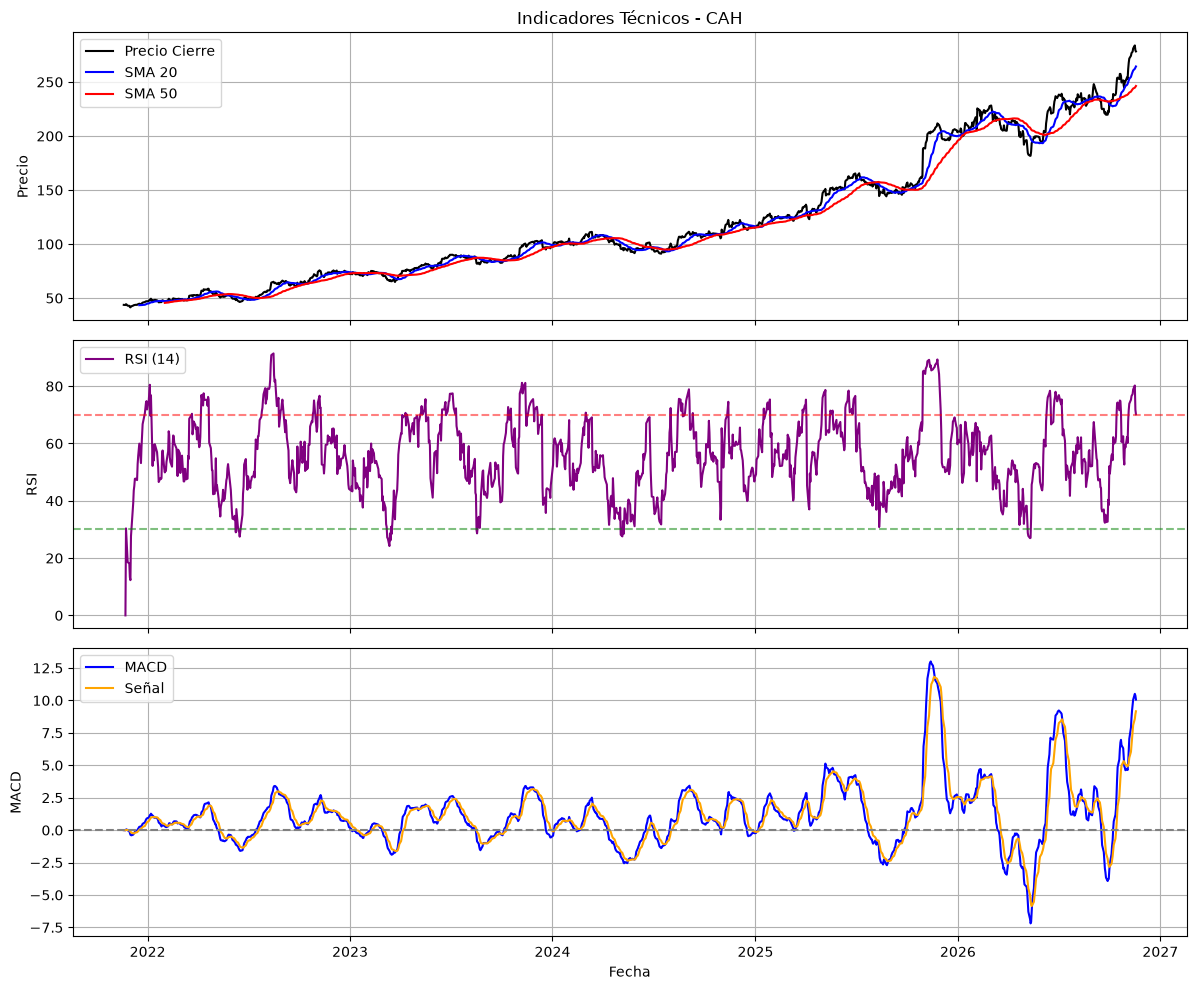


Generando gráficos para: TRGP


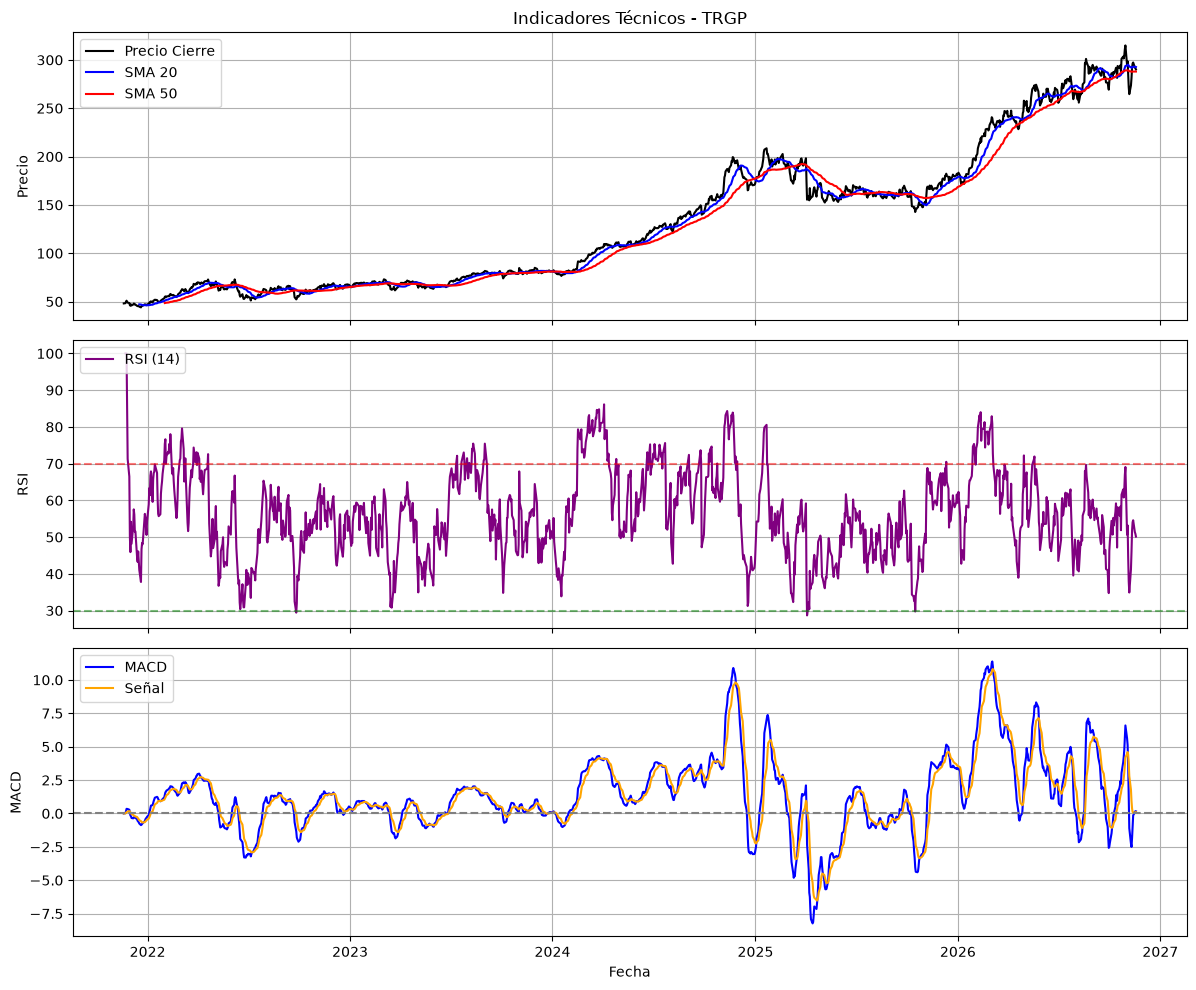


Generando gráficos para: HWM


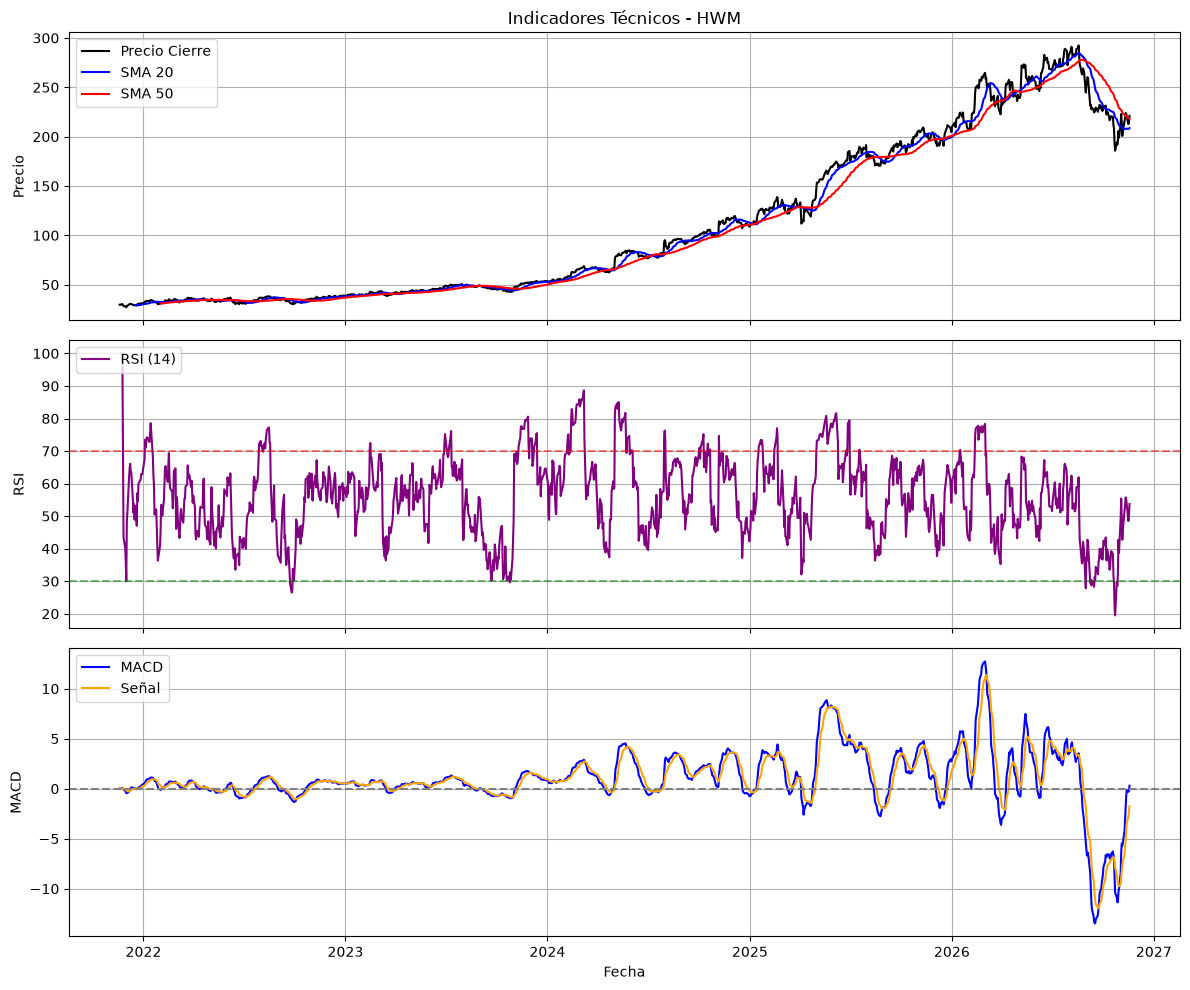


Generando gráficos para: LLY


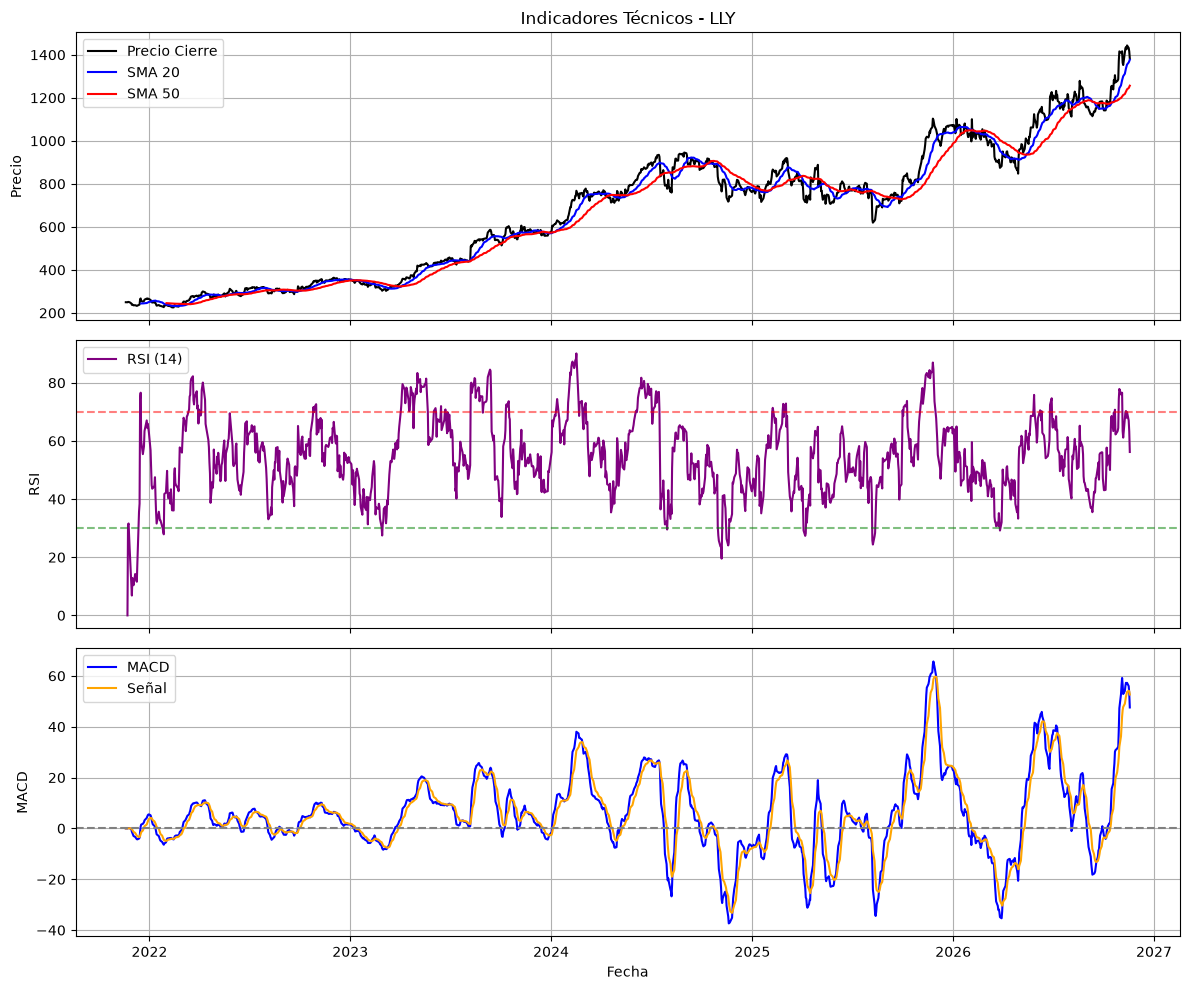


Generando gráficos para: TRV


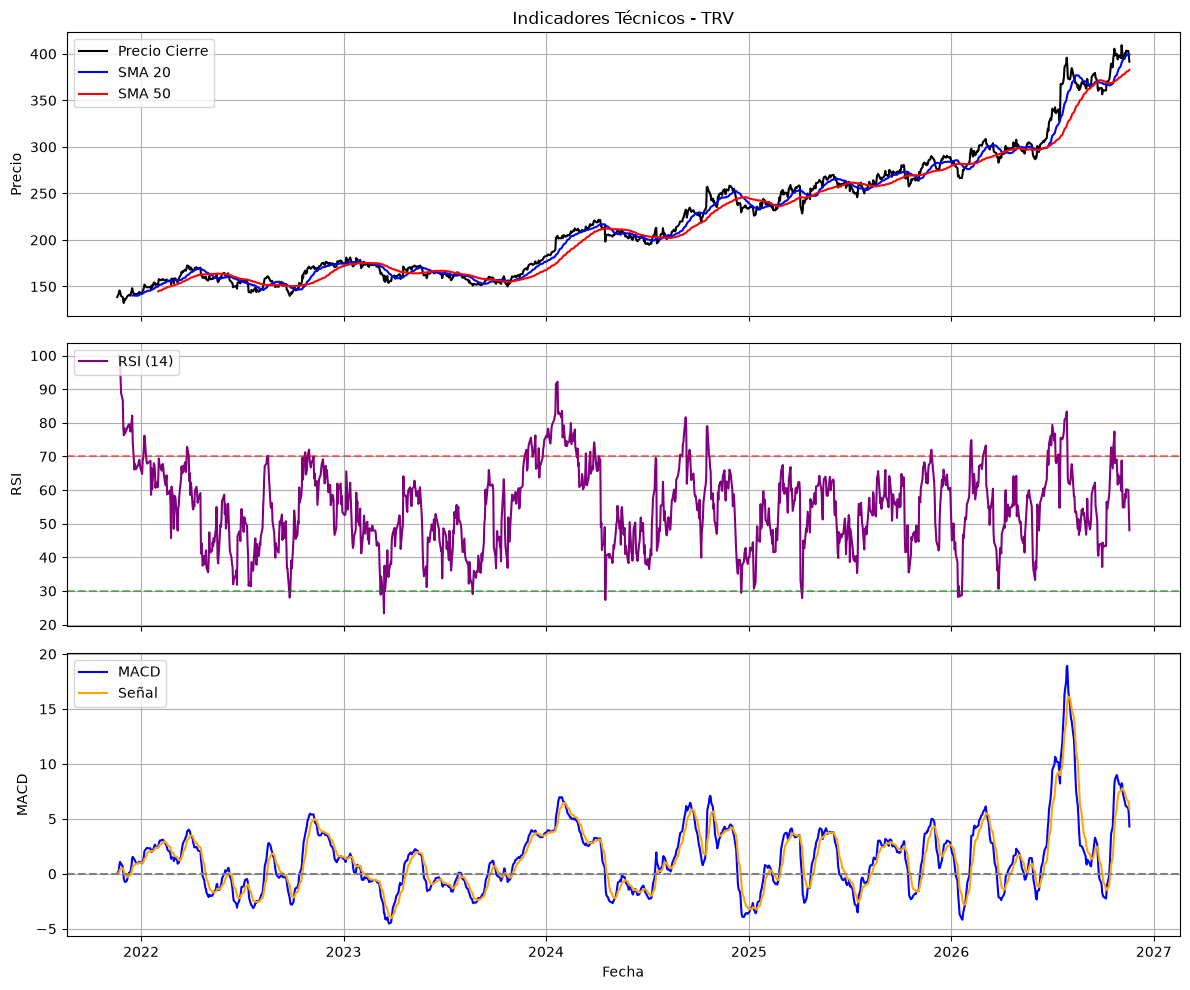

In [42]:
import matplotlib.pyplot as plt
import pandas as pd

print("=" * 70)
print("          ANÁLISIS TÉCNICO DETALLADO: TOP 5 ACCIONES")
print("=" * 70)
print(top_tickers)

for ticker in top_tickers:
    print(f"\nGenerando gráficos para: {ticker.upper()}")

    # Preparar los datos
    df_tec = acciones_validas[ticker].copy()
    df_tec['Date'] = pd.to_datetime(df_tec['Date'])
    df_tec = df_tec.set_index('Date').sort_index()

    # 1. Medias Móviles Simples (SMA 20 y 50)
    df_tec['SMA_20'] = df_tec['Close'].rolling(window=20).mean()
    df_tec['SMA_50'] = df_tec['Close'].rolling(window=50).mean()

    # 2. RSI 14 (Wilder, misma función que en la Fase 3.1)
    df_tec['RSI_14'] = calcular_rsi(df_tec['Close'], 14)

    # 3. MACD
    ema_12 = df_tec['Close'].ewm(span=12, adjust=False).mean()
    ema_26 = df_tec['Close'].ewm(span=26, adjust=False).mean()
    df_tec['MACD'] = ema_12 - ema_26
    df_tec['MACD_Senal'] = df_tec['MACD'].ewm(span=9, adjust=False).mean()

    # Filtrar solo el último año bursátil para una mejor visualización (252 días)
    df_graf = df_tec.tail(1825)

    # Crear la figura con 3 subgráficos
    fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

    # Gráfico 1: Precio y Medias Móviles
    ax1.plot(df_graf.index, df_graf['Close'], label='Precio Cierre', color='black')
    ax1.plot(df_graf.index, df_graf['SMA_20'], label='SMA 20', color='blue')
    ax1.plot(df_graf.index, df_graf['SMA_50'], label='SMA 50', color='red')
    ax1.set_title(f'Indicadores Técnicos - {ticker.upper()}')
    ax1.set_ylabel('Precio')
    ax1.legend()
    ax1.grid(True)

    # Gráfico 2: RSI
    ax2.plot(df_graf.index, df_graf['RSI_14'], color='purple', label='RSI (14)')
    ax2.axhline(70, color='red', linestyle='--', alpha=0.5)
    ax2.axhline(30, color='green', linestyle='--', alpha=0.5)
    ax2.set_ylabel('RSI')
    ax2.legend(loc='upper left')
    ax2.grid(True)

    # Gráfico 3: MACD
    ax3.plot(df_graf.index, df_graf['MACD'], color='blue', label='MACD')
    ax3.plot(df_graf.index, df_graf['MACD_Senal'], color='orange', label='Señal')
    ax3.axhline(0, color='gray', linestyle='--')
    ax3.set_ylabel('MACD')
    ax3.set_xlabel('Fecha')
    ax3.legend(loc='upper left')
    ax3.grid(True)

    plt.tight_layout()
    plt.show()